In [41]:
import seaborn as sb
import pandas as pd

In [23]:
df = sb.load_dataset("penguins")
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [24]:
type(df)

pandas.core.frame.DataFrame

In [25]:
df.sample(10, random_state=42)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,Male
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,Female
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,Female
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,Female
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,Female
329,Gentoo,Biscoe,48.1,15.1,209.0,5500.0,Male
319,Gentoo,Biscoe,51.1,16.5,225.0,5250.0,Male
260,Gentoo,Biscoe,42.7,13.7,208.0,3950.0,Female
114,Adelie,Biscoe,39.6,20.7,191.0,3900.0,Female
220,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,Female


In [26]:
df.columns.tolist()

['species',
 'island',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sex']

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [43]:
df.isna().sum()

pandas.core.series.Series

In [29]:
print(df["species"].value_counts(dropna=False), "\n\n", df["island"].value_counts(dropna=False), "\n\n", df["sex"].value_counts(dropna=False))

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64 

 island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64 

 sex
Male      168
Female    165
NaN        11
Name: count, dtype: int64


In [30]:
df[["species"]]

,species
0,Adelie
1,Adelie
2,Adelie
3,Adelie
4,Adelie
...,...
339,Gentoo
340,Gentoo
341,Gentoo
342,Gentoo


In [31]:
df.columns.tolist()

['species',
 'island',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sex']

In [32]:
from penguins_project.data import validate_penguins

In [33]:
validated_df = validate_penguins(df)
validated_df.shape

(344, 7)

In [34]:
import pytest
import pandera.pandas as pa
broken_df = df.copy()
broken_df.loc[0, "species"] = "Dragon"

with pytest.raises(pa.errors.SchemaErrors) as error:
    validate_penguins(broken_df)
print("Dragon" in str(error.value))

True


In [35]:
from pathlib import Path
ROOT_PATH = Path.cwd().parent
ROOT_PATH

WindowsPath('C:/coding/code/penguins-ml-project')

In [36]:
RAW_PATH = ROOT_PATH / "data" / "raw" / "Penguins.parquet"
RAW_PATH

WindowsPath('C:/coding/code/penguins-ml-project/data/raw/Penguins.parquet')

In [37]:
from penguins_project.data import validate_penguins

df = validate_penguins(df)

In [38]:
#RAW_PATH.mkdir(parents=True, exist_ok=True)
df.to_parquet(path=RAW_PATH, engine="pyarrow", index=False)
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [39]:
df_parquet = pd.read_parquet(RAW_PATH)
print(df_parquet.head(), "\n\n", df_parquet.info(), "\n\n", df_parquet.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7     

In [55]:
from penguins_project.train import (
    MODEL_DATA_PATH,
    ASSIGNMENTS_PATH,
    ID_COLUMN,
    MODEL_FEATURES,
    TARGET_COLUMN,
)

In [56]:
model_data = pd.read_parquet(MODEL_DATA_PATH)
assignments = pd.read_parquet(ASSIGNMENTS_PATH)

In [57]:
merged_data = model_data.merge(
    assignments,
    on=ID_COLUMN,
    validate="one_to_one"
)

In [58]:
train_df = merged_data[merged_data['split']=='train'].copy()
train_df.shape

(239, 9)

In [59]:
import matplotlib.pyplot as plt

sb.set_theme(style="whitegrid", context="notebook")

SPECIES_ORDER = [
    "Adelie",
    "Chinstrap",
    "Gentoo",
]

SPECIES_PALETTE = {
    "Adelie": "#4C78A8",
    "Chinstrap": "#F58518",
    "Gentoo": "#54A24B",
}

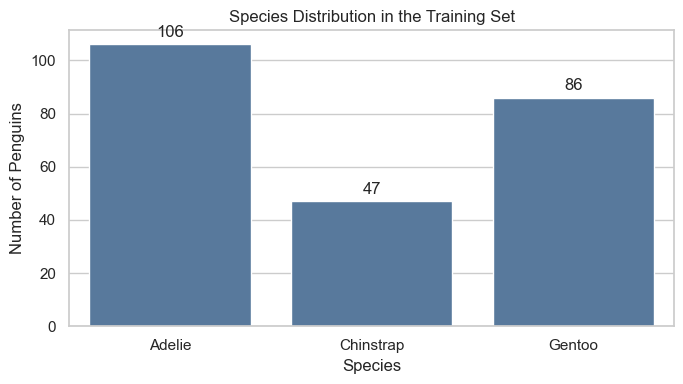

In [60]:
fig, ax = plt.subplots(figsize=(7, 4))

sb.countplot(
    data=train_df,
    x=TARGET_COLUMN,
    order=SPECIES_ORDER,
    color="#4C78A8",
    ax=ax,
)

ax.bar_label(
    ax.containers[0],
    padding=3,
)

ax.set_title("Species Distribution in the Training Set")
ax.set_xlabel("Species")
ax.set_ylabel("Number of Penguins")

plt.tight_layout()
plt.show()

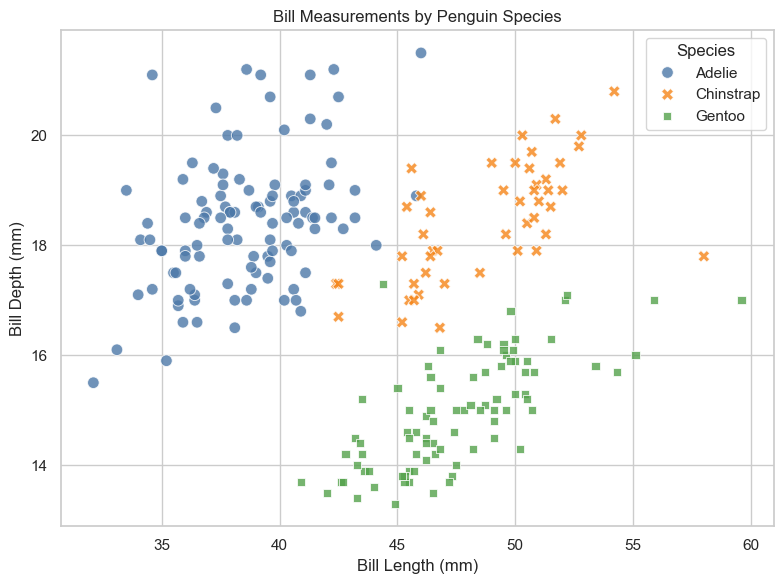

In [61]:
fig, ax = plt.subplots(figsize=(8, 6))

sb.scatterplot(
    data=train_df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue=TARGET_COLUMN,
    style=TARGET_COLUMN,
    hue_order=SPECIES_ORDER,
    style_order=SPECIES_ORDER,
    palette=SPECIES_PALETTE,
    s=70,
    alpha=0.8,
    ax=ax,
)

ax.set_title("Bill Measurements by Penguin Species")
ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.legend(title="Species")

plt.tight_layout()
plt.show()

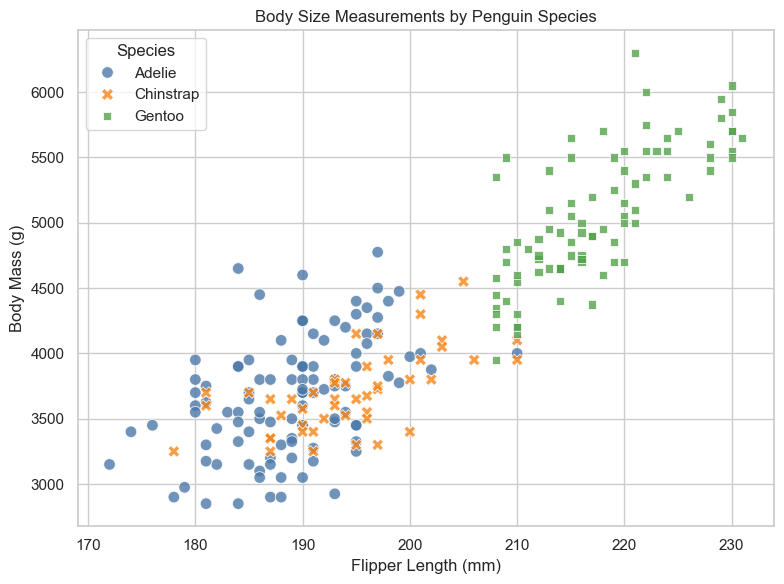

In [62]:
fig, ax = plt.subplots(figsize=(8, 6))

sb.scatterplot(
    data=train_df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue=TARGET_COLUMN,
    style=TARGET_COLUMN,
    hue_order=SPECIES_ORDER,
    style_order=SPECIES_ORDER,
    palette=SPECIES_PALETTE,
    s=70,
    alpha=0.8,
    ax=ax,
)

ax.set_title("Body Size Measurements by Penguin Species")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Body Mass (g)")
ax.legend(title="Species")

plt.tight_layout()
plt.show()

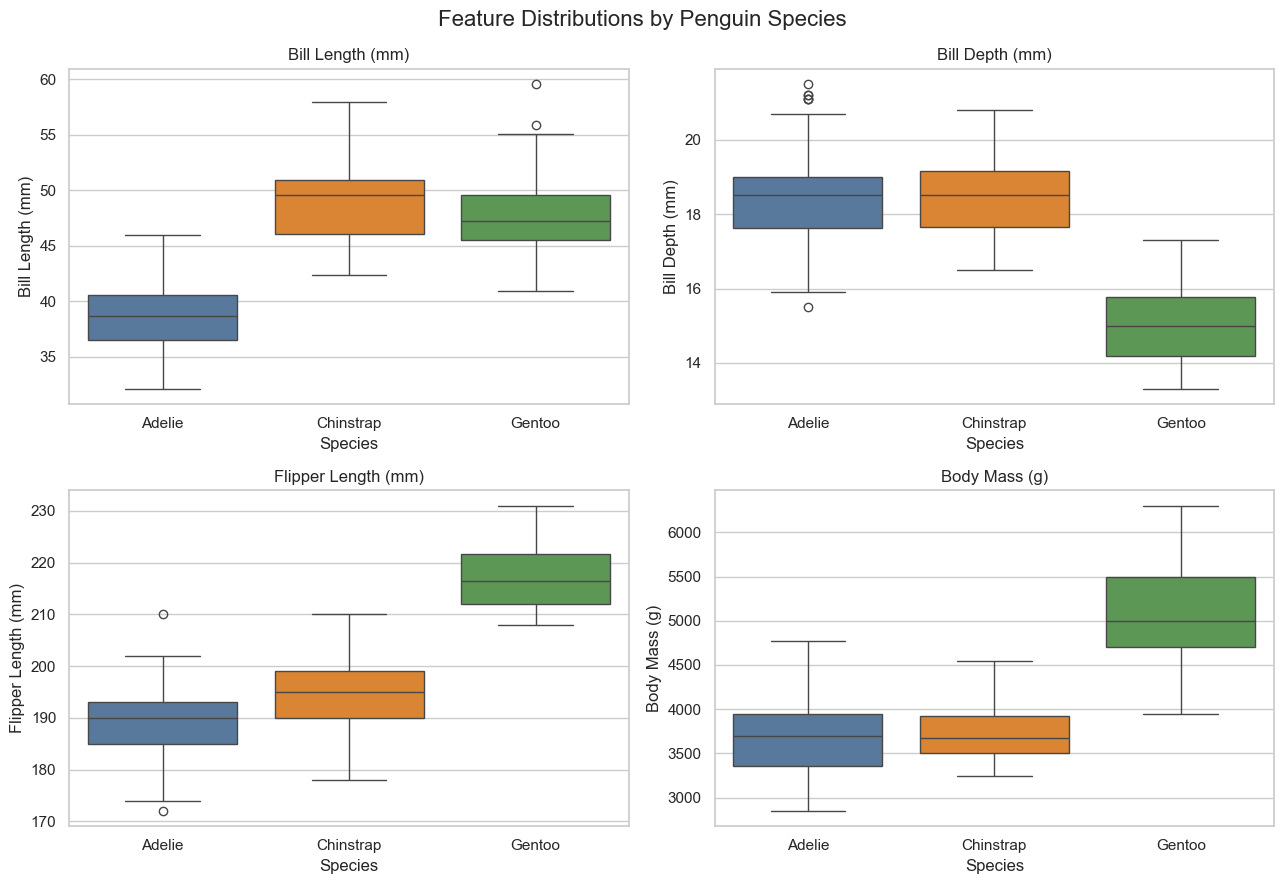

In [63]:
FEATURE_LABELS = {
    "bill_length_mm": "Bill Length (mm)",
    "bill_depth_mm": "Bill Depth (mm)",
    "flipper_length_mm": "Flipper Length (mm)",
    "body_mass_g": "Body Mass (g)",
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13, 9),
)

for ax, feature in zip(axes.flat, MODEL_FEATURES):
    sb.boxplot(
        data=train_df,
        x=TARGET_COLUMN,
        y=feature,
        order=SPECIES_ORDER,
        hue=TARGET_COLUMN,
        hue_order=SPECIES_ORDER,
        palette=SPECIES_PALETTE,
        dodge=False,
        legend=False,
        ax=ax,
    )

    ax.set_title(FEATURE_LABELS[feature])
    ax.set_xlabel("Species")
    ax.set_ylabel(FEATURE_LABELS[feature])

fig.suptitle(
    "Feature Distributions by Penguin Species",
    fontsize=16,
)

plt.tight_layout()
plt.show()